# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import AiRoundDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/airound/aerial/",
    "csv_file": "./data/airound/aerial/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = AiRoundDataset(dataset_config)

## Show images from the dataset

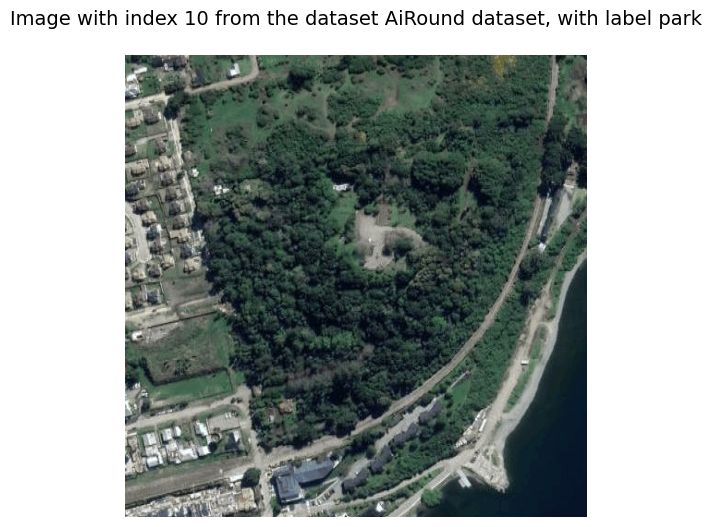

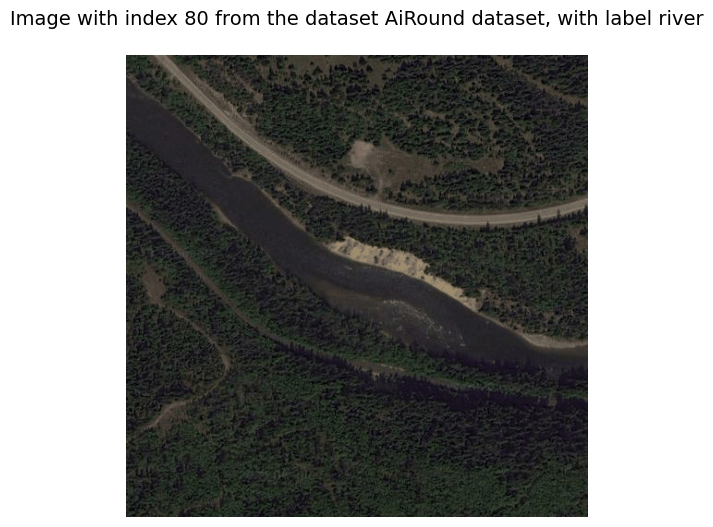

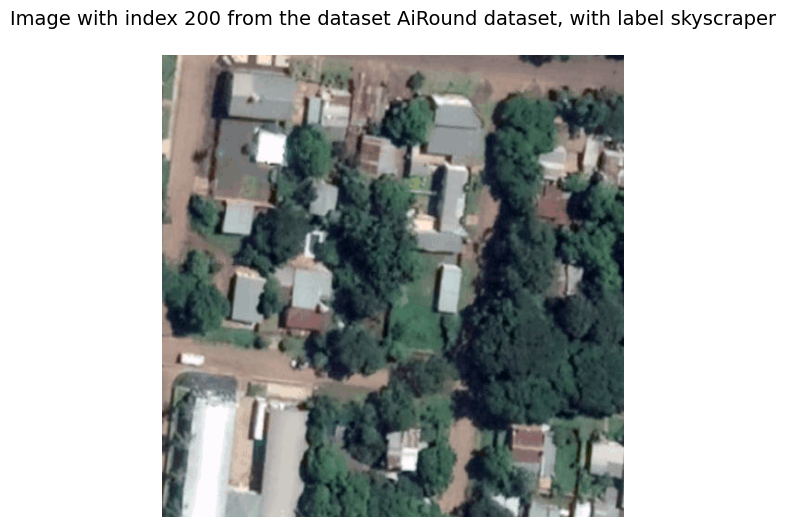

In [5]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

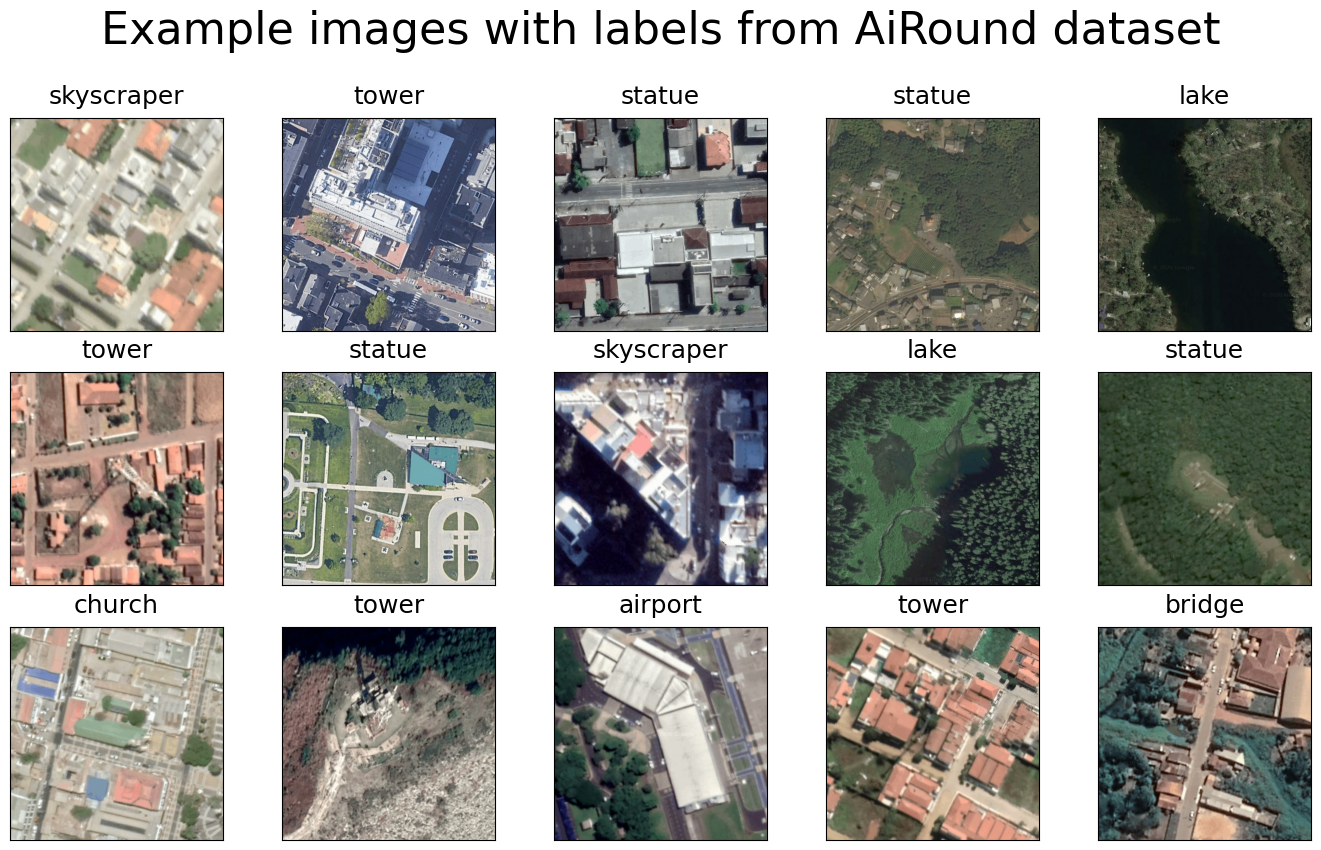

In [6]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.show_samples()

,File name,Label
0,church/477536516.png,church
1,statue/5731344826.png,statue
2,park/667618426.png,park
3,lake/550521363.png,lake
4,bridge/703253328.png,bridge
5,lake/49305118.png,lake
6,river/799751528.png,river
7,forest/184225284.png,forest
8,statue/5256765535.png,statue
9,stadium/217.png,stadium


In [8]:
dataset.data_distribution_table()

,Label,Count
0,airport,752
1,bridge,790
2,church,972
3,forest,864
4,lake,784
5,park,839
6,river,933
7,skyscraper,889
8,stadium,811
9,statue,934


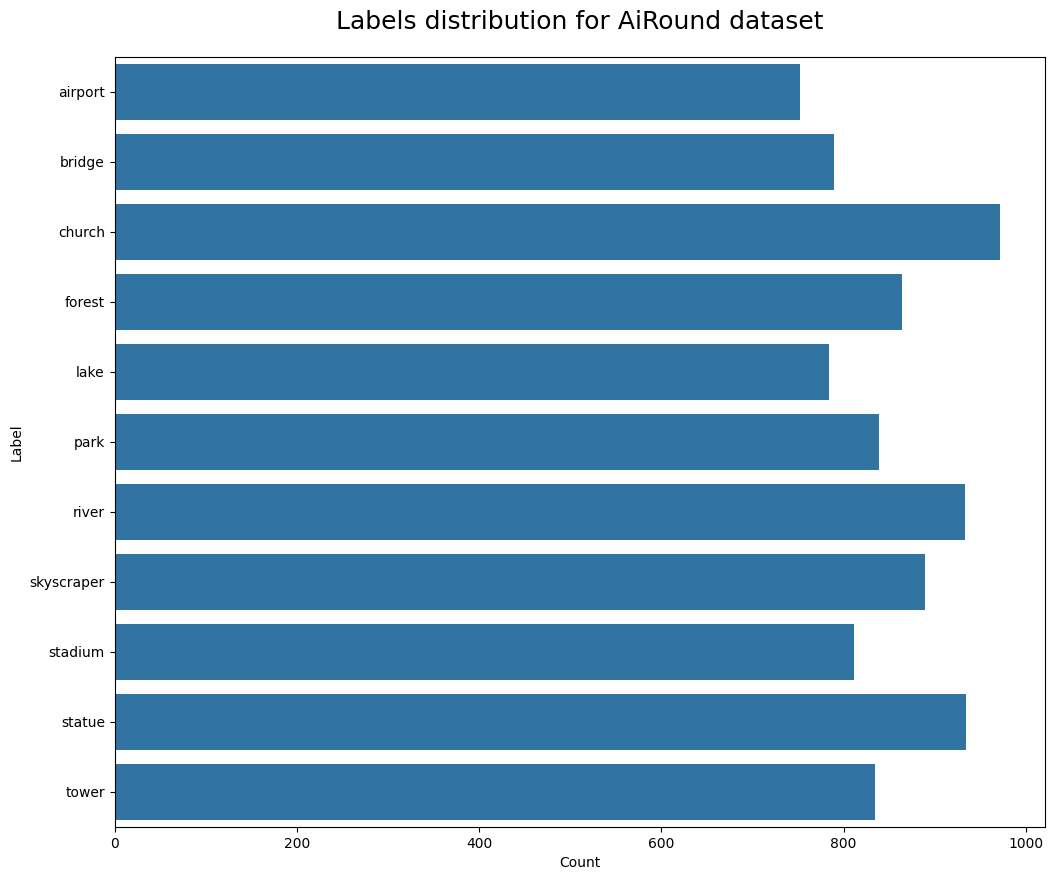

In [9]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/airound/aerial/",
    "csv_file": "./data/airound/aerial/train.csv",
}

train_dataset = AiRoundDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/airound/aerial/",
    "csv_file": "./data/airound/aerial/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = AiRoundDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(9403, 1175)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/airound/aerial/"
model_config = {
    "num_classes": 11, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-19 14:02:44,092 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-19 14:02:44,283 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [16]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-19 14:02:44,410 INFO Starting training.
training: 100%|██████████| 294/294 [01:12<00:00,  4.04it/s]
2025-05-19 14:03:57,249 INFO epoch: 1, time: 73, loss:  0.91290
testing on train set: 100%|██████████| 294/294 [00:32<00:00,  8.99it/s]
2025-05-19 14:04:31,764 INFO Accuracy:0.8399446985004786, Precision Micro:0.8399446985004786, Precision Macro:0.8507284669813111, Precision Weighted:0.8479692061171955, Precision per Class:[0.91506849 0.92541436 0.8256538  0.96840442 0.7997936  0.93695921
 0.80206379 0.75835721 0.95524297 0.7709438  0.70011148], Recall Micro:0.8399446985004786, Recall Macro:0.8437323726724508, Recall Weighted:0.8399446985004786, Recall per Class:[0.88829787 0.84810127 0.68209877 0.70949074 0.98852041 0.9034565
 0.91639871 0.89313836 0.92108508 0.77837259 0.75209581], F1_score Micro:0.839944698500478, F1_score Macro:0.8427285857585499, F1_score Weighted:0.8393913910075389, F1_score per Class:[0.90148448 0.88507266 0.74704225 0.81897128 0.88419852 0.91990291
 0.855

0.2069005043512581

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/airound/aerial/",
    "csv_file": "./data/airound/aerial/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = AiRoundDataset(test_dataset_config)
model_path = "./data/experiments/airound/aerial/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-19 14:21:38,463 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/airound/aerial/checkpoint.pth.tar
2025-05-19 14:21:38,811 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/airound/aerial/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 74/74 [00:04<00:00, 17.33it/s]


[{'Accuracy': 0.84},
 {'Precision Micro': 0.84,
  'Precision Macro': 0.8501615002648237,
  'Precision Weighted': 0.8459526675427287,
  'Precision per Class': array([0.88172043, 0.91666667, 0.78301887, 0.84920635, 0.91      ,
         0.98484848, 0.80152672, 0.73049645, 0.85148515, 0.84482759,
         0.7979798 ])},
 {'Recall Micro': 0.84,
  'Recall Macro': 0.8426707392114843,
  'Recall Weighted': 0.8400000000000001,
  'Recall per Class': array([0.95348837, 0.83809524, 0.74774775, 0.8699187 , 0.92857143,
         0.68421053, 0.8974359 , 0.91150442, 0.93478261, 0.81666667,
         0.68695652])},
 {'F1_score Micro': 0.8399999999999993,
  'F1_score Macro': 0.84188170997835,
  'F1_score Weighted': 0.8386563482800435,
  'F1_score per Class': array([0.91620112, 0.87562189, 0.76497696, 0.85943775, 0.91919192,
         0.80745342, 0.84677419, 0.81102362, 0.89119171, 0.83050847,
         0.73831776])}]

## Predictions

2025-05-19 14:22:09,044 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/airound/aerial/checkpoint.pth.tar
2025-05-19 14:22:09,324 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/airound/aerial/checkpoint.pth.tar at epoch 11


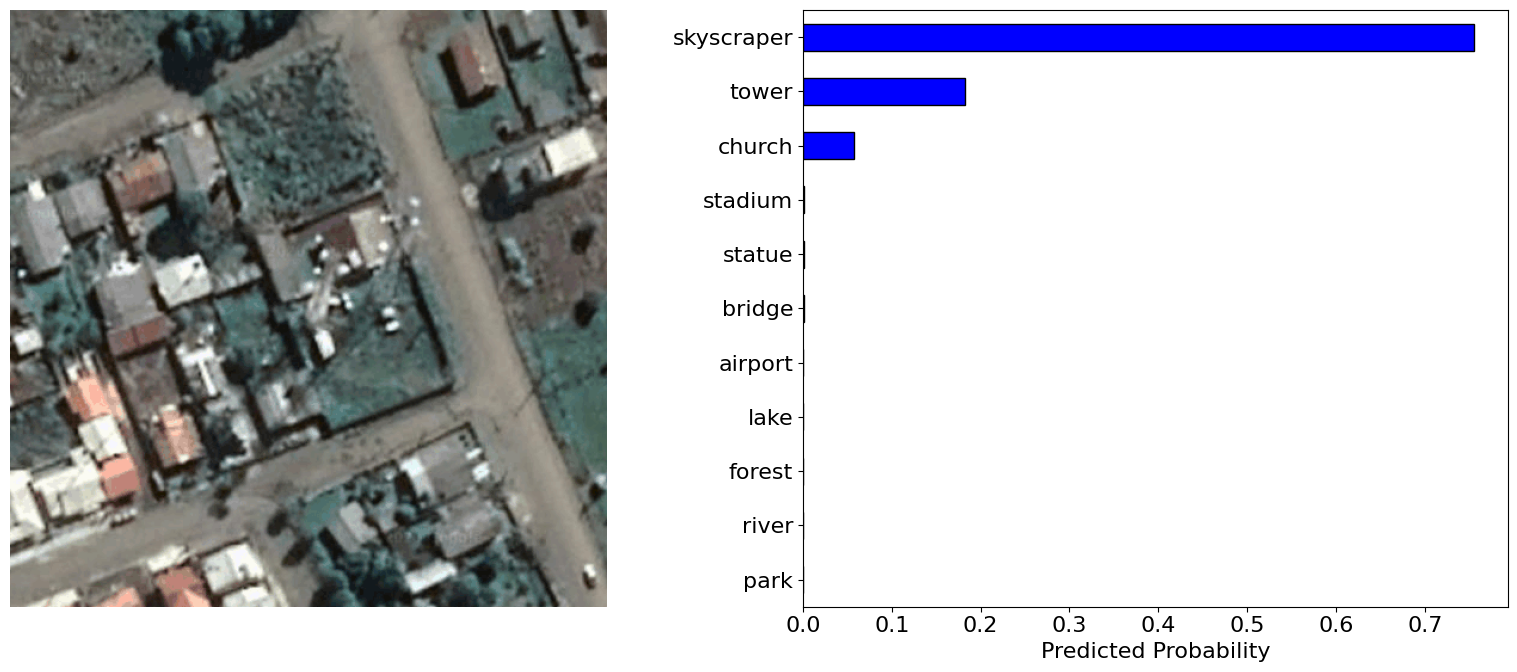

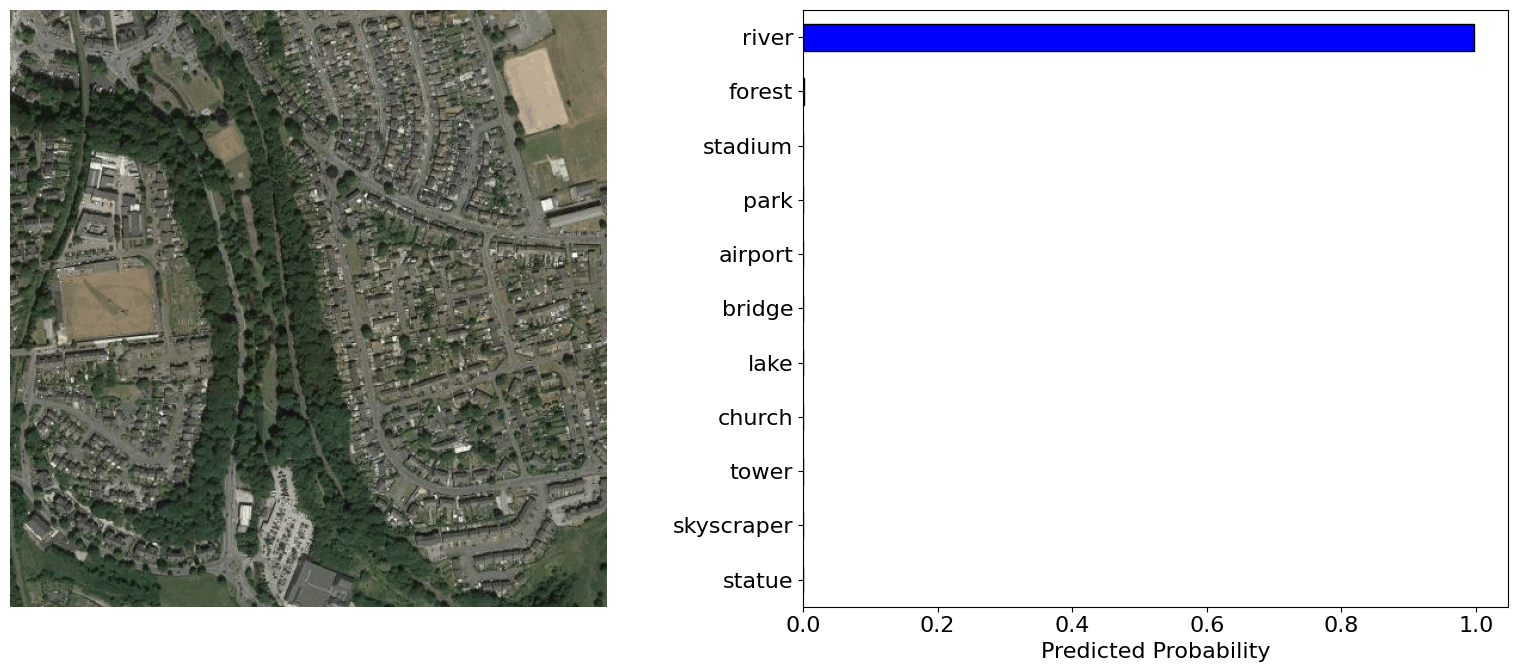

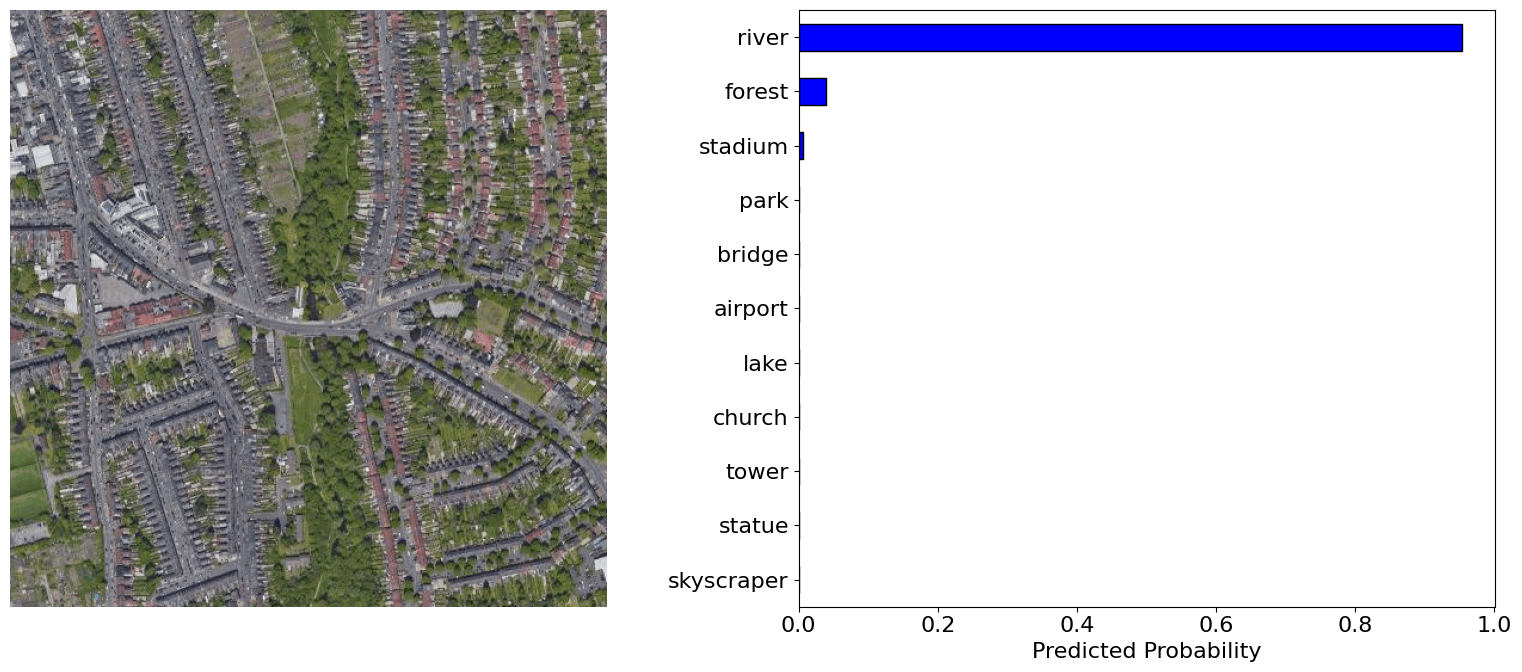

In [ ]:
labels = ["airport","bridge","church","forest","lake","park","river","skyscraper","stadium","statue","tower"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/airound/aerial/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/airound/aerial/tower/6345910500.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/airound/aerial/forest/148098578.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/airound/aerial/river/1303663610.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)